# 35. RG3 유형별 탐지 모델 — 가스 / 미성형 학습·테스트

34번 스캔 결과를 모델로 옮겨 검증.

| 대상 | 규칙(학습 없음) | 비지도 (정상 reference) | 지도 (Run 하나씩 빼고) | 중첩 (정직한 추정) |
|---|---|---|---|---|
| 가스 | 쿠션위치 직전10샷 std | maha_std4 | rf_std4 | nested_top3 |
| 미성형 | 계량시간 편차20 | maha_short6 | rf_short6 | nested_top3 |

- ⚠ 규칙의 변수는 labeled 전체 스캔(34번)을 보고 고른 것 → 낙관적. **`nested_top3`가 정직한 추정치** (각 Run을 뺄 때마다 남은 Run으로만 변수 선택)
- 경보 임계값은 정상 reference 백분위(q=0.99/0.995) → 라벨 미사용
- `순열 p`: 같은 Run 안에서 라벨을 섞은 무작위 대비. 0.05 미만이어야 '무작위보다 낫다'

In [1]:
import pandas as pd
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 70)
from plot_style import set_style; set_style()
import rg3_type_models as M
R = M.run('rg3')

[rg3] labeled 629샷 | 정상 reference 4,359샷 | 실시간 변수 99개
  평가 대상: {'정상': 595, '가스': 22, '미성형': 10}
  가스 완료
  미성형 완료


## 1. 가스 탐지

In [2]:
cols = ['모델', '대상 샷', 'AP', '기준선(불량률)', 'AP/기준선', '순열 p (vs 무작위)', '유의', '전체 상위10%', 'Run별 상위10%',
        'q0.99 경보', 'q0.99 TP', 'q0.99 FP', 'q0.99 정밀도', 'q0.995 경보', 'q0.995 TP', 'q0.995 FP']
display(R['eval_가스'][[c for c in cols if c in R['eval_가스']]].round(3))
print('중첩 모델이 Run마다 고른 변수 (안정적으로 같은 변수가 뽑히는지)')
display(R['picks_가스'])

,모델,대상 샷,AP,기준선(불량률),AP/기준선,순열 p (vs 무작위),유의,전체 상위10%,Run별 상위10%,q0.99 경보,q0.99 TP,q0.99 FP,q0.99 정밀도,q0.995 경보,q0.995 TP,q0.995 FP
0,rule_cushion_std,22,0.096,0.036,2.691,0.235,-,7/22,5/22,4.0,0.0,4.0,0.000,4.0,0.0,4.0
1,maha_std4,22,0.051,0.036,1.432,0.522,-,3/22,1/22,19.0,1.0,18.0,0.053,15.0,1.0,14.0
2,rf_std4,22,0.115,0.036,3.218,0.002,O,8/22,9/22,16.0,3.0,13.0,0.188,11.0,2.0,9.0
3,nested_top3,22,0.041,0.036,1.146,0.082,-,4/22,2/22,20.0,1.0,19.0,0.050,20.0,1.0,19.0
4,final_maha (기준),22,0.050,0.036,1.402,0.466,-,3/22,2/22,NaN,NaN,NaN,NaN,NaN,NaN,NaN


중첩 모델이 Run마다 고른 변수 (안정적으로 같은 변수가 뽑히는지)


,대상,뺀 Run,학습 대상 샷,선택1,선택2,선택3
0,가스,rg3_R1,22,"Cushion_Position|직전10샷std (↑, δ=+0.45)","맥락|Run안순서 (↓, δ=-0.33)","Injection_Time|직전10샷std (↑, δ=+0.30)"
1,가스,rg3_R2,18,"Cushion_Position|직전10샷std (↑, δ=+0.52)","Injection_Time|직전10샷std (↑, δ=+0.35)","Barrel_Temperature_2|직전10샷std (↓, δ=-0.35)"
2,가스,rg3_R3,16,"Cushion_Position|직전10샷std (↑, δ=+0.54)","Plasticizing_Time|직전10샷std (↓, δ=-0.36)","Injection_Time|직전10샷std (↑, δ=+0.34)"
3,가스,rg3_R4,19,"Barrel_Temperature_2|직전10샷std (↓, δ=-0.43)","Cushion_Position|직전10샷std (↑, δ=+0.40)","Barrel_Temperature_5|직전10샷std (↑, δ=+0.37)"
4,가스,rg3_R5,18,"Cushion_Position|직전10샷std (↑, δ=+0.46)","맥락|Run안순서 (↓, δ=-0.35)","금형온도4−3|수준 (↑, δ=+0.32)"
5,가스,rg3_R6,17,"Barrel_Temperature_3|직전10샷std (↓, δ=-0.38)","Cushion_Position|직전10샷std (↑, δ=+0.36)","Barrel_Temperature_2|직전10샷std (↓, δ=-0.34)"
6,가스,rg3_R7,22,"Cushion_Position|직전10샷std (↑, δ=+0.45)","Barrel_Temperature_2|직전10샷std (↓, δ=-0.33)","Injection_Time|직전10샷std (↑, δ=+0.28)"
7,가스,rg3_R8,22,"Cushion_Position|직전10샷std (↑, δ=+0.45)","Barrel_Temperature_2|직전10샷std (↓, δ=-0.33)","Injection_Time|직전10샷std (↑, δ=+0.28)"


## 2. 미성형 탐지

In [3]:
display(R['eval_미성형'][[c for c in cols if c in R['eval_미성형']]].round(3))
display(R['picks_미성형'])

,모델,대상 샷,AP,기준선(불량률),AP/기준선,순열 p (vs 무작위),유의,전체 상위10%,Run별 상위10%,q0.99 경보,q0.99 TP,q0.99 FP,q0.99 정밀도,q0.995 경보,q0.995 TP,q0.995 FP
0,rule_plast_dev,10,0.039,0.017,2.378,0.097,-,2/10,3/10,6.0,0.0,6.0,0.0,3.0,0.0,3.0
1,maha_short6,10,0.019,0.017,1.145,0.658,-,1/10,1/10,5.0,0.0,5.0,0.0,0.0,0.0,0.0
2,rf_short6,10,0.030,0.017,1.842,0.185,-,2/10,1/10,3.0,0.0,3.0,0.0,2.0,0.0,2.0
3,nested_top3,10,0.025,0.017,1.492,0.223,-,0/10,3/10,27.0,0.0,27.0,0.0,23.0,0.0,23.0
4,final_maha (기준),10,0.021,0.017,1.248,0.644,-,0/10,1/10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,대상,뺀 Run,학습 대상 샷,선택1,선택2,선택3
0,미성형,rg3_R1,10,"Plasticizing_Time|편차20 (↑, δ=+0.48)","Barrel_Temperature_5|직전10샷std (↑, δ=+0.47)","Cushion_Position|직전10샷std (↑, δ=+0.45)"
1,미성형,rg3_R2,9,"Barrel_Temperature_5|직전10샷std (↑, δ=+0.55)","Plasticizing_Time|편차20 (↑, δ=+0.49)","Hopper_Temperature|직전변화 (↓, δ=-0.44)"
2,미성형,rg3_R3,6,"Hopper_Temperature|직전10샷std (↓, δ=-0.59)","Cycle_Time|직전10샷std (↑, δ=+0.56)","Mold_Temperature_4|직전변화 (↓, δ=-0.46)"
3,미성형,rg3_R4,9,"Plasticizing_Time|편차20 (↑, δ=+0.61)","Cushion_Position|직전10샷std (↑, δ=+0.55)","Barrel_Temperature_5|직전10샷std (↑, δ=+0.48)"
4,미성형,rg3_R5,8,"Hopper_Temperature|직전10샷std (↓, δ=-0.56)","Barrel_Temperature_5|직전10샷std (↑, δ=+0.53)","Plasticizing_Time|편차20 (↑, δ=+0.52)"
5,미성형,rg3_R6,8,"Barrel_Temperature_5|직전10샷std (↑, δ=+0.57)","Hopper_Temperature|직전10샷std (↓, δ=-0.43)","Plasticizing_Time|편차20 (↑, δ=+0.42)"
6,미성형,rg3_R7,10,"Barrel_Temperature_5|직전10샷std (↑, δ=+0.49)","Plasticizing_Time|편차20 (↑, δ=+0.48)","Cushion_Position|직전10샷std (↑, δ=+0.46)"
7,미성형,rg3_R8,10,"Barrel_Temperature_5|직전10샷std (↑, δ=+0.49)","Plasticizing_Time|편차20 (↑, δ=+0.48)","Cushion_Position|직전10샷std (↑, δ=+0.46)"


## 3. PR 곡선

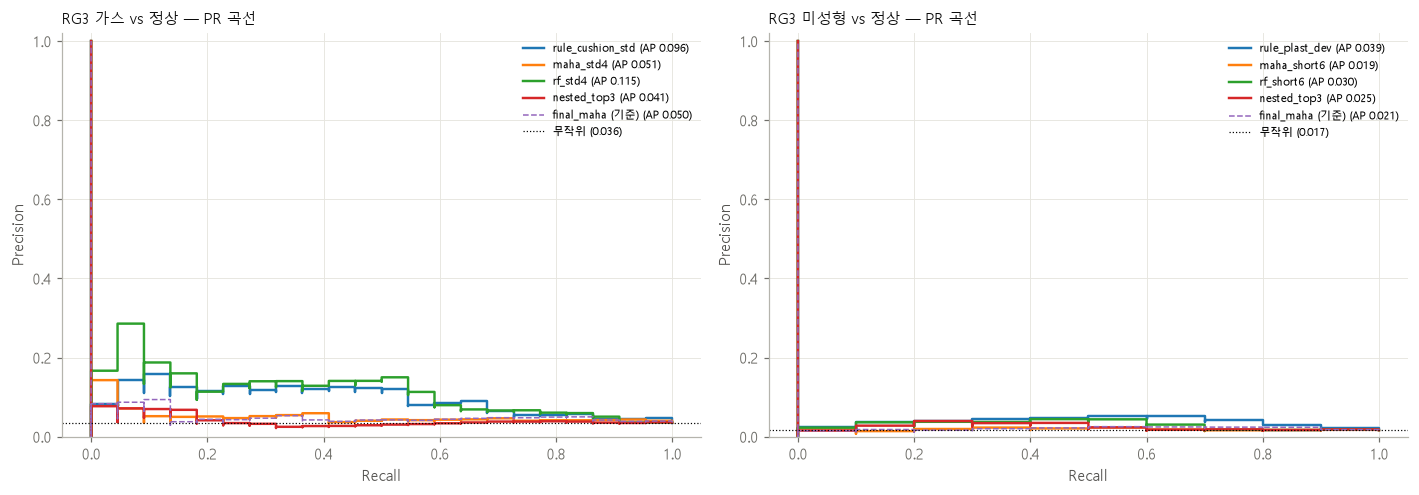

In [4]:
M.plot_pr(R, save='./outputs/rg3_type_models/pr.png')